In [1]:
from gammapy.data import DataStore, EventList, Observations, Observation, FixedPointingInfo
from gammapy.irf import load_irf_dict_from_file
from gammapy.maps import WcsGeom, MapAxis
from gammapy.makers import MapDatasetMaker, SafeMaskMaker, FoVBackgroundMaker
from gammapy.datasets import MapDataset, Datasets, FluxPointsDataset
from gammapy.modeling.models import FoVBackgroundModel, PowerLawSpectralModel, GaussianSpatialModel, SkyModel, Models
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

from basil.map_basil import MapDatasetBASiL
from basil.utils import reshape_comb, compute_comb_3D, reshape_likelihoods, create_significance_map, significance_3D_fluxpoint

import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from regions import CircleSkyRegion
from collections import defaultdict
from astropy.io import fits
import math
import copy
from astropy.coordinates import Angle

# Contents

This notebook presents the steps for performing a 3D spectral analysis with BASiL in Gammapy. 
It utilizes IRFs from the public test data release from H.E.S.S., as distributed alongside Gammapy.
The event lists were generated by Monte Carlo and fake GAMMANESS (gamma/hadron separation variable) and likelihood values were created just for this example.
The user must provide its own data and attribute likelihood values to the measured events.

Suggested folder structure:

```
project_folder/
└── run_<ID>/
    └── basil_factors/
        └── likelihoods/

```

It may be necessary to change the path in all uses of `file_path` if adapted otherwise.

**Summary**:

I) Dataset creation.

II) Significance.

III) Model fitting and spectrum.


# I) Dataset creation - Stacked analysis

- MapDataset is created normally, once observations, geometry and safe masks are defined.
- Event lists already contain the likelihood values (`LIKE_SIG`, `LIKE_BKG`) assigned for given `GAMMANESS` values and energy bin.
- Template code is provided


In [ ]:
%env GAMMAPY_DATA= #Set the path to gammapy-data

In [3]:
project_folder = './example_data/Gaussian'

In [4]:
# Load observations
obs_ids = [23523, 23523, 23523, 23523]
datastore = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1/")
observations_ = datastore.get_observations(obs_ids, required_irf=["aeff", "edisp", "psf"])
pos = observations_[0].meta.target.position

# Create new observations with replacement event lists
list_events = []
observations = Observations()
for i in range(len(obs_ids)):
    events_ = EventList.read(project_folder+"/run{:}/events_gaussian_run{:}_likelihood.fits".format(i,i))
    irfs = load_irf_dict_from_file('$GAMMAPY_DATA/hess-dl3-dr1/data/hess_dl3_dr1_obs_id_023523.fits.gz') 
    pointing = FixedPointingInfo(fixed_icrs=events_.pointing_radec)
    livetime = events_.observation_live_time_duration

    obs = Observation.create(
        pointing=pointing,
        livetime=livetime,
        irfs=irfs,
        obs_id=i
    )    

    obs._events = events_
    observations.append(obs)
    list_events.append(events_)

In [5]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 
e_true = np.logspace(-1, 2, 49) * u.TeV 

energy_axis = MapAxis.from_edges(e_reco, unit='TeV', name='energy', interp='log')
energy_axis_true = MapAxis.from_edges(e_true, unit='TeV', name="energy_true", interp='log')

en_bins = energy_axis.edges.value

offset_max = 2*u.deg

geom = WcsGeom.create(
    skydir=pos,
    binsz=0.02,
    width=(8, 8),
    frame="icrs",
    proj="CAR",
    axes=[energy_axis],)

maker = MapDatasetMaker()

safe_mask_maker = SafeMaskMaker(
                       methods=["offset-max", 'aeff-max', 'aeff-default', 'edisp-bias', 'bkg-peak'],
                       offset_max=offset_max, bias_percent=10, aeff_percent=10,
                   )

circle0 = CircleSkyRegion(
    center=SkyCoord(pos.icrs.ra, pos.icrs.dec), radius=0.5* u.deg
)

excl_regions = []
excl_regions.append(circle0)


exclusion_mask0 = geom.region_mask(regions=excl_regions, inside=False)
maker_fov0 = FoVBackgroundMaker(method="fit", exclusion_mask=exclusion_mask0)

stacked_dataset =  MapDataset.create(
                      geom = geom, 
                      name = "3d_map",  
                      energy_axis_true = energy_axis_true
                   )

list_excl_mask = []
en_thres_run = []
datasets_joint = Datasets()
for i, obs in enumerate(observations):
    cutout = stacked_dataset.cutout(
        obs.get_pointing_icrs(obs.tmid), width=2 * offset_max, name="run"+str(i)
    )
    dataset = maker.run(cutout, obs)
    dataset = safe_mask_maker.run(dataset, obs)
    
    bkg_model = FoVBackgroundModel(dataset_name=dataset.name)
    dataset.models=bkg_model
    dataset.background_model.spectral_model.tilt.frozen = False
    dataset = maker_fov0.run(dataset)

    stacked_dataset.stack(dataset)
    datasets_joint.append(dataset)
    list_excl_mask.append(dataset.mask.interp_to_geom(geom))
    en_thres_run.append(np.argwhere(dataset.mask_safe.data == True)[0][0])



In [ ]:
'''
    Template code to obtain the event likelihoods based on binned distributions.
    Code does not work as it stands!
    For simplicity, likelihood values are attributed back to the event lists (zero value if event does not participate).

'''

def compute_like_events(n_on, event_var_bin, density_sig, points_sig, density_bkg, points_bkg):
    """
       Template for attributing likelihood values based on binned distributions. 
    """

    like_bkg = np.array([])
    like_sig = np.array([])

    for j in range(n_on):
        # Find where in the histogram is the var_Non[j] value is and find the density value
        if np.argwhere(points_sig < event_var_bin[j]).size > 1:
            indx_sig = np.argwhere(points_sig < event_var_bin[j])[-1][0]
            if (indx_sig == len(density_sig)): #border case
                indx_sig -= 1
        else:
            indx_sig = 0
            
        # Repeat for background distribution
        if np.argwhere(points_bkg < event_var_bin[j]).size > 1:
            indx_bkg = np.argwhere(points_bkg < event_var_bin[j])[-1][0]
            if (indx_bkg == len(density_bkg)):
                indx_bkg -= 1
        else:
            indx_bkg = 0
            
        like_sig = np.append(like_sig, sig_density)
        like_bkg = np.append(like_bkg, bkg_density)

    return like_sig, like_bkg


for i in range(len(datasets_joint)):
    # Load event list
    events1 = list_events[i]
    energy_events = events1.table["ENERGY"]
    zeta_events = events1.table["GAMMANESS"]

    likesig_events = np.zeros(len(events1.table))
    likebkg_events = np.zeros(len(events1.table))
    for j in range(len(en_bins)-1):
        mask_en = (energy_events >= en_bins[j]) & (energy_events < en_bins[j+1])
        try:
            gamma_dist = np.load()
            proton_dist = np.load()
    
            density_sig, points_sig = np.histogram(gamma_dist, bins=bins_gamma, density=True)
            density_bkg, points_bkg = np.histogram(proton_dist, bins=bins_bkg, density=True)

            zeta_array = np.asarray(zeta_events[mask_en])
            N = len(zeta_array)
            like_sig, like_bkg = compute_like_events(N, zeta_array, density_sig, points_sig, density_bkg, points_bkg)

            likesig_events[mask_en] = like_sig
            likebkg_events[mask_en] = like_bkg
        except Exception as e:
            print(f"Failed at energy bin {j}")

    events1.table['LIKE_SIG'] = likesig_events
    events1.table['LIKE_BKG'] = likebkg_events

# Saving new event lists
for i in range(len(list_events)):
    primary_hdu = fits.PrimaryHDU()
    hdu_evt = fits.BinTableHDU(list_events[i].table)
    hdu_all = fits.HDUList([primary_hdu, hdu_evt])
    #hdu_all.writeto(project_folder+'/run{:}/events_run{:}_likelihood.fits'.format(i,i))


## Combinatory factors

Computation of BASiL factors from likelihood values. Adapted specifically for the case in which the likelihoods are in the event lists.

In [6]:
for i in range(len(datasets_joint)):
    # Load event list
    events1 = list_events[i]
    pixel_indx1 = stacked_dataset.geoms.get('geom').coord_to_pix((events1.table['RA'], events1.table['DEC'], events1.table['ENERGY']))
    pixel_indx1_r = stacked_dataset.geoms.get('geom').coord_to_idx((events1.table['RA'], events1.table['DEC'], events1.table['ENERGY']))

    # Insert in the EventList
    if 'INDX_RA' in events1.table.colnames:
        events1.table.replace_column('INDX_RA', pixel_indx1_r[0])
    else:
        events1.table.add_column(pixel_indx1_r[0], name='INDX_RA')
        
    if 'INDX_DEC' in events1.table.colnames:
        events1.table.replace_column('INDX_DEC', pixel_indx1_r[1])
    else:
        events1.table.add_column(pixel_indx1_r[1], name='INDX_DEC')

comb, like_sig_data, like_bkg_data = compute_comb_3D(stacked_dataset, list_events, en_thres_run, list_excl_mask)

In [7]:
# Create BASiL dataset

#dataset = MapDataset.read('./Sources/MC/'+folder_sim+'/dataset_stacked_standard_'+label_name+'_offset0-5_norm'+str(norm_value)+'_nocuts.yaml')
dataset_basil = MapDatasetBASiL()

dataset_basil.counts = stacked_dataset.counts
dataset_basil.exposure = stacked_dataset.exposure
dataset_basil.background = stacked_dataset.background
dataset_basil.psf = stacked_dataset.psf
dataset_basil.edisp = stacked_dataset.edisp
dataset_basil.mask_safe = stacked_dataset.mask_safe
dataset_basil.mask_fit = stacked_dataset.mask_fit
dataset_basil.stat_type = 'basil'



In [8]:
'''

Due to optimization purposes and code structure, the combinatory lists `comb` are reshaped and flattened.


`new_comb`: list for stat_array() computation.

`flat_comb_masked`: list for stat_sum() computation.

'''

new_comb, flat_comb_masked = reshape_comb(comb, dataset_basil)
new_like_sig_data, new_like_bkg_data = reshape_likelihoods(like_sig_data, like_bkg_data, dataset_basil)

In [9]:
dataset_basil.comb = new_comb
dataset_basil.comb_flat = np.asanyarray(flat_comb_masked)


# II) Significance map

In [12]:
energy_bin = 5
sig_max = 5

significance_map = create_significance_map(energy_bin, sig_max, dataset_basil, new_like_sig_data, new_like_bkg_data, correlation_radius=Angle("0.2 deg"))

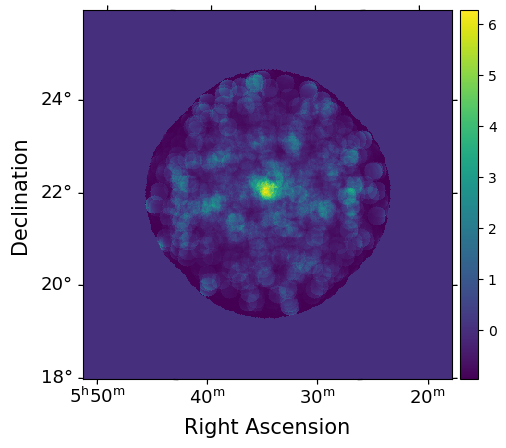

In [13]:

ax = significance_map.plot(cmap='viridis', add_cbar=True)
#ax.contourf(mask_outside, levels=[-0.5,0.5], colors='white')

ax.set_xlabel('Right Ascension', fontsize=15)
ax.set_ylabel('Declination', fontsize=15)
ax.tick_params(axis='both', labelsize=13)


# III) Model fitting

In [10]:
spatial_model = GaussianSpatialModel(
    lon_0=pos.ra,
    lat_0=pos.dec,
    sigma=0.2*u.deg,
    frame='icrs'
)

spectral_model = PowerLawSpectralModel(
    index=2.2,
    amplitude=1e-11 * u.Unit("cm-2 s-1 TeV-1"),
    reference="1 TeV",
)

model_s = SkyModel(
    spatial_model=spatial_model,
    spectral_model=spectral_model,
    name="extended-source"
)

model_s.spatial_model.parameters['lon_0'].min = pos.ra.value - 0.7
model_s.spatial_model.parameters['lon_0'].max = pos.ra.value + 0.7
model_s.spatial_model.parameters['lat_0'].min = pos.dec.value - 0.7
model_s.spatial_model.parameters['lat_0'].max = pos.dec.value + 0.7

dataset_basil.models = Models([model_s])
fit = Fit()
# Fit results
result_fit = fit.run(datasets=dataset_basil)

In [11]:
result_fit

In [12]:
result_fit.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
,index,2.1612e+00,,1.151e-01,nan,nan,False,,
,amplitude,1.0239e-11,TeV-1 s-1 cm-2,2.006e-12,nan,nan,False,,
,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,lon_0,8.3603e+01,deg,3.192e-02,8.293e+01,8.433e+01,False,,
,lat_0,2.2029e+01,deg,2.846e-02,2.131e+01,2.271e+01,False,,
,sigma,1.7282e-01,deg,1.999e-02,0.000e+00,nan,False,,
,e,0.0000e+00,,0.000e+00,0.000e+00,1.000e+00,True,,
,phi,0.0000e+00,deg,0.000e+00,nan,nan,True,,


## Spectrum 

In [13]:
e_reco = np.logspace(-1, 2, 13) * u.TeV 

fpe = FluxPointsEstimator(
    energy_edges=e_reco, source="extended-source", selection_optional="all",
)

flux_points_basil_stacked = fpe.run(datasets=dataset_basil)

flux_points_dataset_stacked = FluxPointsDataset(
    data=flux_points_basil_stacked, models=dataset_basil.models
)



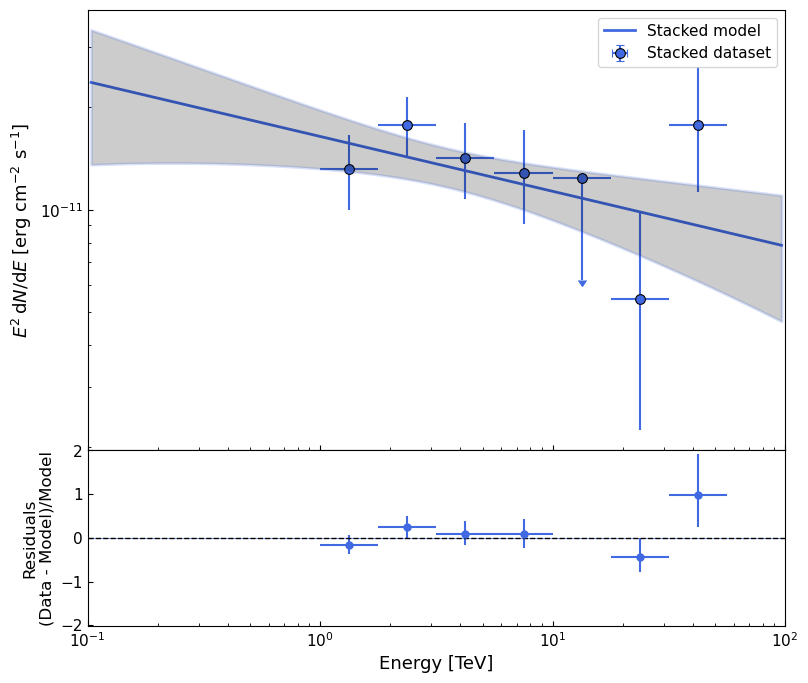

In [14]:
### Plotting the spectra

# First dataset: stacked
kwargs_spectrum_stacked = {
    "kwargs_fp": {
        "color": "royalblue",
        "marker": "o",
        "markersize": 7,
        "markeredgecolor": "black",
        "markeredgewidth": 0.8,
        "ls": "none",
        "label": "Stacked dataset",
        "zorder": 5,
    },
    "kwargs_model": {
    "color": "royalblue",
    "ls": "-",
    "linewidth": 2,
    "label": "Stacked model",
    }
}

kwargs_residuals_stacked = {
    "color": "royalblue",
    "marker": "o",
    "markersize": 5,
    "ls": "none",
}


# Plot stacked dataset
ax_spectrum, ax_residuals = flux_points_dataset_stacked.plot_fit(
    kwargs_spectrum=kwargs_spectrum_stacked,
    kwargs_residuals=kwargs_residuals_stacked,
)


ax_spectrum.set_xlabel("Energy [TeV]", fontsize=13)
ax_spectrum.set_ylabel(
    r"$E^2\,{\rm d}N/{\rm d}E$ [erg cm$^{-2}$ s$^{-1}$]",
    fontsize=13,
)

ax_spectrum.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)

ax_spectrum.legend(
    fontsize=11,
    loc="best",
)

# Residual panel
ax_residuals.axhline(
    0, color="black", linestyle="--", lw=1
)

ax_residuals.set_xlabel("Energy [TeV]", fontsize=13)
ax_residuals.set_ylabel("Residuals"+"\n"+"(Data - Model)/Model", fontsize=12)

ax_residuals.tick_params(
    axis="both", which="both", direction="in",
    top=False, right=False, labelsize=11
)


fig = ax_spectrum.figure
fig.set_size_inches(9, 8)

fig.subplots_adjust(hspace=0)



In [15]:
for i in range(4,11):
    log_pH0, sigma = significance_3D_fluxpoint(dataset_basil, i, 1.0239e-11, 5)
    print(sigma)

3.5346378965533876
5.605309055404368
4.187525746943929
3.305470592590229
-0.5796279171092598
0.41857917241981435
4.2520661884451
